## Claim Verification Results on the Time Split data

In [44]:
MODEL_NAME_MAPPING = {
    # 'gpt-4.1': 'GPT 4.1',
    # 'Meta-Llama-3.1-70B-Instruct': 'Llama 3.1',
    # 'Mixtral-8x7B-Instruct-v0.1': 'Mixtral',
    'gpt-5.2': 'GPT 5.2',
    # 'Llama-4-Scout-17B-16E-Instruct': 'Llama 4',
    'Llama-3.2-3B-Instruct': 'Llama 3.2 [3B]',
    'gemma-4-31B-it': 'Gemma 4'
}

PARTITION = 'dev'
VERSION = '2026.06.09'
DATASET = 'civicfactnew'

In [45]:
import numpy as np
import subprocess
import seaborn as sns

sns.set_style('whitegrid')
from utils import add_bar_labels, pop_model_size, read_jsonl, savefig
from utils.metabar import plot_metadatabar_chart

def ci_95(series):
    return (series.quantile(0.025), series.quantile(0.975))

ERR_KWS={'linewidth': 1, 'color': '#00000099'}


def create_and_filter_model_names(df):
    df["model"] = df['filepath.model_dir'].str.split("__").str[-1].apply(lambda x: MODEL_NAME_MAPPING.get(x))
    df = df[~df.model.isna()]
    df.loc[~df['filepath.train_data_version'].isna(), 'model'] += ' (FT)'
    df.loc[df.model.str.contains('(FT)', regex=False), 'model'] += ' c' + df['filepath.config']
    return df


In [46]:
doc_df = read_jsonl(f'../data/civicfact-{VERSION}/document_chunks.jsonl.gz')
ft_docs = set(doc_df[doc_df['document.content_source'] != 'pubmed']['document.pmid'].unique())
doc_df['document.pmid'] = doc_df['document.pmid'].astype(str)
doc_df.head()

,acronyms,chunk.end,chunk.id,chunk.overlap,chunk.size,chunk.start,chunk.text,document.content_source,document.length,document.pmid,document.total_chunks,license,partition,passages,pubtator
0,"[{'defn': 'non-small cell lung cancer', 'name'...",1000,26870817:0-1000,100,1000,0,P-glycoprotein Mediates Ceritinib Resistance i...,pmc,44838,26870817,50,CC BY-NC-ND,train,"[{'passage.end': 113, 'passage.section': 'titl...","[{'match.end': 14.0, 'match.start': 0.0, 'matc..."
1,"[{'defn': 'non-small cell lung cancer', 'name'...",1900,26870817:900-1900,100,1000,900,p/ABCB1) overexpression as a ceritinib resista...,pmc,44838,26870817,50,CC BY-NC-ND,train,"[{'passage.end': 1586, 'passage.section': 'abs...","[{'match.end': 938.0, 'match.start': 929.0, 'm..."
2,"[{'defn': 'non-small cell lung cancer', 'name'...",2800,26870817:1800-2800,100,1000,1800,t not to alectinib and PF-06463922.\n*\nCeriti...,pmc,44838,26870817,50,CC BY-NC-ND,train,"[{'passage.end': 1944, 'passage.section': 'abs...","[{'match.end': 1847.0, 'match.start': 1838.0, ..."
3,"[{'defn': 'non-small cell lung cancer', 'name'...",3700,26870817:2700-3700,100,1000,2700,"stance, suggesting that P-gp expression could ...",pmc,44838,26870817,50,CC BY-NC-ND,train,"[{'passage.end': 2810, 'passage.section': 'abs...","[{'match.end': 2855.0, 'match.start': 2829.0, ..."
4,"[{'defn': 'non-small cell lung cancer', 'name'...",4600,26870817:3600-4600,100,1000,3600,ORR; 65% (113/173) vs 20% (34/174) in the seco...,pmc,44838,26870817,50,CC BY-NC-ND,train,"[{'passage.end': 4436, 'passage.section': 'art...","[{'match.end': 4412.0, 'match.start': 4398.0, ..."


In [47]:

inputs = subprocess.check_output(["find",  "../results/claim_verification",  "-regex",  '.*evaluations.*civicfactnew.*/.*all.processed.jsonl.gz']).decode().split('\n')

inputs = [f.strip() for f in inputs if f.strip() and '_f0.' not in f]
print(f'found {len(inputs)} matching input files')
print(inputs)

df = read_jsonl(*inputs, add_filename=True, add_filepath_metadata=True)
df['correct'] = df.gold_label_name == df.predicted_label_name
df['document.pmid'] = df['document.pmid'].astype(str)
df['id'] = df['claim.flat'] + ':' + df['document.pmid'].astype(str) + df['evidence.flat']

df = df.merge(doc_df[['document.pmid', 'document.content_source']].drop_duplicates())
df = df[df['document.content_source'] != 'pubmed']
df = df.rename(columns={"freq": "dataset_size"})


for col in [
    'filepath.chat_template',
    'filepath.data_version',
    'filepath.embedding_mode',
    'filepath.eval_dataset',
    'filepath.generation_config',
    'filepath.pairing_mode',
    'filepath.prompt_template',
    'filepath.ret_model',
    'filepath.subsample_filter',
    'filepath.train_data_version',
    'filepath.train_prompt_template',
]:
    if col not in df:
        df[col] = None

df = df[
    # (df['filepath.prompt_template'].fillna('none').isin({'none', 'labelfirst', 'verboselimit100'}))
    (df['filepath.data_version'].isin({VERSION}))
    & (~df['filepath.train_dataset'].isin({'civicfactx5000g8'}))
    & (df['filepath.subsample_fraction'].astype(float).fillna(1) == 1)
]
df['document.pmid'] = df['document.pmid'].astype(str)

df = df.merge(doc_df[['document.pmid', 'document.content_source']].drop_duplicates())

print(df.shape)
df['subset'] = df['filepath.subsample_filter'].fillna('all')
df = create_and_filter_model_names(df)

# filter on model best param picks
# df = df[(~df.model.isin({'Mixtral', 'Llama 3.1'})) | (df['filepath.prompt_template'] == 'verifyevidence')]
# df = df[(~df.model.isin({'Mixtral', 'Llama 3.1', 'Llama 4-Scout'})) | (df['filepath.examples'].astype(float) == 30)]

print(df.filename.nunique(), 'files after filtering')


df['retrieval'] =  df['filepath.ret_model']
df.loc[df.retrieval == 'random42', 'retrieval'] = 'Random'
df.loc[df.retrieval == 'head-oracle', 'retrieval'] = 'Oracle'
df.loc[~df['filepath.eval_dataset'].str.contains('pairs'), 'retrieval'] = 'Human'
df.loc[df['filepath.eval_dataset'] == 'civicfactft', 'retrieval'] = 'Full-Text'

if df[df.model.str.contains('(FT)', regex=False)].model.nunique() == 1:
    print(df.model.unique())
    df['model'] = df['model'].str.replace(r'\[\dB\] \(FT\).*', '(FT)', regex=True)


df.loc[df['document.content_source'] != 'pubmed','document.content_source' ] = 'PMC'

print('total claim/document/retrieval pairs', df['id'].nunique())
print('new submission pairs', df[df.gold_label_name == 'SUPPORTS']['id'].nunique())

data_df = df

previous_count = df[['model', 'filepath.train_data_version', 'filepath.data_version', 'model', 'filepath.eval_dataset']].drop_duplicates().shape[0]
df[['model', 'filepath.train_dataset', 'filepath.config', 'filepath.data_version', 'filepath.eval_dataset', 'filepath.ret_model']].drop_duplicates().sort_values(['model', 'filepath.train_dataset', 'filepath.data_version', 'filepath.eval_dataset'])

found 8 matching input files
['../results/claim_verification/fine-tuning/config-16/completion/civicfactchunk-2026.03.03/chat-default/prompts.verifyevidencetrain.0-shot.train.jsonl/meta-llama__Llama-3.2-3B-Instruct/evaluations/civicfactnewpairs-medcpt-goat-L5000-qt0-2026.06.09/chat-default/gen-5/prompts.verifyevidencetrain.0-shot.all.processed.jsonl.gz', '../results/claim_verification/fine-tuning/config-16/completion/civicfactchunk-2026.03.03/chat-default/prompts.verifyevidencetrain.0-shot.train.jsonl/meta-llama__Llama-3.2-3B-Instruct/evaluations/civicfactnewpairs-qwen-mongoose-L5000-qt0-2026.06.09/chat-default/gen-5/prompts.verifyevidencetrain.0-shot.all.processed.jsonl.gz', '../results/claim_verification/evaluations/meta-llama__Meta-Llama-3.1-70B-Instruct/civicfactnewpairs-medcpt-goat-L5000-qt0-2026.06.09/chat-default/gen-12/prompts.verifyevidence.15-shot.all.processed.jsonl.gz', '../results/claim_verification/evaluations/mistralai__Mixtral-8x7B-Instruct-v0.1/civicfactnewpairs-medcpt-

,model,filepath.train_dataset,filepath.config,filepath.data_version,filepath.eval_dataset,filepath.ret_model
546,GPT 5.2,NaN,NaN,2026.06.09,civicfactnewpairs,medcpt-goat
637,GPT 5.2,NaN,NaN,2026.06.09,civicfactnewpairs,qwen-mongoose
455,Gemma 4,NaN,NaN,2026.06.09,civicfactnewpairs,medcpt-goat
0,Llama 3.2 (FT),civicfactchunk,16,2026.06.09,civicfactnewpairs,medcpt-goat
91,Llama 3.2 (FT),civicfactchunk,16,2026.06.09,civicfactnewpairs,qwen-mongoose


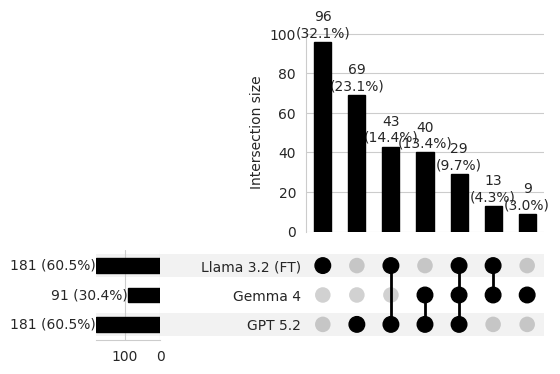

In [48]:

import upsetplot


def pick_label(labels):
    if labels.nunique() == 1:
        return labels.tolist()[0]
    if labels.isna().all():
        return None
    if 'SUPPORTS' in labels:
        return 'SUPPORTS'
    return 'REVISIONS'




fig_df = df.drop(columns=['predicted_label_name']).merge(df.groupby(['model', 'id', 'gold_label_name']).agg({'predicted_label_name': pick_label}).reset_index())
fig_df['set_id'] = fig_df['id'] + ' ' + fig_df.predicted_label_name

# fig_df = fig_df[fig_df.model.isin({'Llama 3.2 (FT)', 'Gemma 4', 'GPT 5.2'})]

calls = {}

for model, subset_df in fig_df.groupby('model'):
    calls[model] = set(subset_df['set_id'].unique().tolist())

# for label, subset_df in fig_df.groupby('predicted_label_name'):
#     calls[label] = set(subset_df['set_id'].unique().tolist())

# for (content_source), subset_df in fig_df.groupby('document.content_source'):
#     calls[f'{content_source}'] = set(subset_df['id'].unique().tolist())

# for (content_source), subset_df in fig_df.groupby('retrieval'):
#     calls[f'{content_source}'] = set(subset_df['id'].unique().tolist())


contents = upsetplot.from_contents(calls)
fig = upsetplot.plot(contents, sort_by='cardinality', sort_categories_by='input', show_percentages=True, show_counts=True)

## TODO: manual review the ones where all models failed
## TODO: manual review the ones where only FT model failed and only FT model success?


In [49]:
## Convert pairs to doccano for review?
import json
import re


def extract_predicted_revision(text):
    text = text.strip()
    m = re.search(r'^(?P<label>SUPPORTS|NEI)\n+(?P<explanation>.*)', text, flags=re.MULTILINE | re.IGNORECASE)
    if m:
        return m.groupdict()
    m = re.search(r'^label: (?P<label>SUPPORTS|NEI)\n+revised claim: none(\n+(explanation: )?(?P<explanation>.*))?', text, flags=re.MULTILINE | re.IGNORECASE)
    if m:
        return m.groupdict()
    m = re.search(r'^label: (?P<label>REVISIONS)\n+revised claim:\n(```json\n)?(?P<revision>\{(.|\n)+\})(```)?\n+(explanation: )?(?P<explanation>.*)', text, flags=re.MULTILINE | re.IGNORECASE)
    if m:
        return m.groupdict()
    m = re.search(r'^(?P<label>REVISIONS)\n+(```json\n)?(?P<revision>\{(.|\n)+\})(```)?\n+(?P<explanation>.*)', text, flags=re.MULTILINE | re.IGNORECASE)
    if m:
        return m.groupdict()
    return None


def normalize_text(text):
    return str(text).lower().replace('-', ' ')


def drop_matched_sections(dict1, dict2):
    drop_keys = []
    for col in set(dict1) & set(dict2):
        if normalize_text(dict1[col]) == normalize_text(dict2[col]):
            drop_keys.append(col)
    return {c: v for c, v in  dict1.items() if c not in drop_keys}, {c: v for c, v in  dict2.items() if c not in drop_keys}


def load_json_as_kv_lines(json_str):
    claim = json.loads(json_str)
    claim_lines = []
    for key in claim:
        value = json.dumps(claim[key], sort_keys=True)
        claim_lines.append(f'"{key}": {value}')
    return claim_lines


def diff_revision(ref, alt):
    if alt  == 'none' or not alt:
        return None, None
    claim = load_json_as_kv_lines(ref)
    revision = load_json_as_kv_lines(alt)

    all_lines = sorted(set(claim) | set(revision))

    diff = []
    for line in all_lines:
        if line in claim and line in revision:
            diff.append('    ' + line)
        elif line in claim:
            diff.append('-   ' + line)
        elif line in revision:
            diff.append('+   ' + line)
        else:
            raise AssertionError('line must be in claim or revision')
    diff = ',\n'.join(diff)
    return '```text\n{\n' + diff + '\n}\n```'

def convert_to_doccano(row):

    text = [
        '# PMID:' + row['document.pmid'],
        'row:' + str(row['row_index']),
        row['retrieval'],
        '```text',
        row['claim.flat'],
        '```',
        row['passages'],
        '',
        '## Expected Response',
        'label: ' + row['gold_label_name'],
        ]
    if row['revised_claim.flat'] != 'none':
        text.extend(['revised claim:\n', diff_revision(row['claim.flat'], row['revised_claim.flat'])])

    text.extend(['', '## Model Response', 'retrieval: ' + row['retrieval']])
    if row['parsed']:
        text.extend([
            'label: ' + row['parsed']['label']
        ])
        if row['parsed'].get('revision') and row['parsed']['revision'] != 'none':
            text.extend(['revised claim:\n', diff_revision(row['claim.flat'], row['parsed']['revision'])])
        if row['parsed']['explanation']:
            text.append('explanation: ' + row['parsed']['explanation'])
    else:
        text.append(row['generated_text'])


    return '\n'.join(text)


def agg_evidence(subset_df):
    assert subset_df.shape[0] <= 2
    ev1 = subset_df.evidence.tolist()[0]
    ret1 = subset_df.retrieval.tolist()[0]
    if subset_df.shape[0] > 1:
        ev2 = subset_df.evidence.tolist()[1]
        ret2 = subset_df.retrieval.tolist()[1]
    else:
        ev2 = None
        ret2 = None


    passages = {}
    for chunk in ev1:
        pid = str(chunk['meta']['start']) + '-' + str(chunk['meta']['end'])
        passages[pid] = {'text': chunk['content'], 'start': chunk['meta']['start'], 'end': chunk['meta']['end'], 'retrieval': [ret1]}
    if ev2:
        for chunk in ev2:
            pid = str(chunk['meta']['start']) + '-' + str(chunk['meta']['end'])
            if pid in passages:
                passages[pid]['retrieval'].append(ret2)
            else:
                passages[pid] = {'text': chunk['content'], 'start': chunk['meta']['start'], 'end': chunk['meta']['end'], 'retrieval': [ret2]}
    passages = sorted(passages.values(), key=lambda p: p['start'])
    all_starts = sorted({p['start'] for p in passages} | {p['end'] for p in passages})
    split_passages = []
    queue = passages[:]
    while queue:
        p = queue.pop(0)
        for s in all_starts:
            if s > p['start'] and s < p['end']:
                relative_split = s - p['start']
                start_p = {**p}
                start_p['end'] = s
                start_p['text'] = p['text'][:relative_split]

                end_p = {**p}
                end_p['start'] = s
                end_p['text'] = p['text'][relative_split:]

                queue.extend([start_p, end_p])
                break
        else:
            split_passages.append(p)

    dedup = {}
    for p in split_passages:
        pid =  str(p['start']) + '-' + str(p['end'])
        if pid in dedup:
            dedup[pid]['retrieval'] = dedup[pid]['retrieval'] + p['retrieval']
        else:
            dedup[pid] = p

    passages = sorted(dedup.values(), key=lambda p: p['start'])

    text = []
    for p in passages:
        retrieval = '; '.join(sorted(set(p['retrieval'])))
        text.append('\n'.join([
            f'\<passage start="{p["start"]}" end="{p["end"]}" retrieval="{retrieval}"\>',
            p['text'],
            '\</passage\>'
        ]))
    return '\n\n'.join(text)

# doccano_df = df.copy()
# doccano_df['parsed'] = doccano_df.generated_text.apply(extract_predicted_revision)
# doccano_df['row_index'] = doccano_df.index.tolist()
# # doccano_df = doccano_df[doccano_df.row_index == 0]


# passages_df = df.drop_duplicates(['claim.flat', 'document.pmid', 'retrieval'])
# passages_df = passages_df.groupby(['claim.flat', 'document.pmid']).apply(lambda subset: agg_evidence(subset)).reset_index(name='passages')

# doccano_df = doccano_df.merge(passages_df)


# doccano_df['revised_claim.flat'] = doccano_df['revised_claim.flat'].fillna('none')
# doccano_df['text'] = doccano_df.apply(convert_to_doccano, axis=1)

# rows = []
# for _, row in doccano_df.drop_duplicates(['claim.flat', 'document.pmid']).iterrows():
#     print(row['text'])
#     print('\n\n\n')

<>:157: SyntaxWarning: invalid escape sequence '\<'
<>:157: SyntaxWarning: invalid escape sequence '\>'
<>:159: SyntaxWarning: invalid escape sequence '\<'
<>:157: SyntaxWarning: invalid escape sequence '\<'
<>:157: SyntaxWarning: invalid escape sequence '\>'
<>:159: SyntaxWarning: invalid escape sequence '\<'
/var/tmp/ipykernel_485180/579560020.py:157: SyntaxWarning: invalid escape sequence '\<'
  f'\<passage start="{p["start"]}" end="{p["end"]}" retrieval="{retrieval}"\>',
/var/tmp/ipykernel_485180/579560020.py:157: SyntaxWarning: invalid escape sequence '\>'
  f'\<passage start="{p["start"]}" end="{p["end"]}" retrieval="{retrieval}"\>',
/var/tmp/ipykernel_485180/579560020.py:159: SyntaxWarning: invalid escape sequence '\<'
  '\</passage\>'


In [50]:
from utils import dump_jsonl


# outputfile = '../../manual_reviews/data/doccano/project_104/input.jsonl'
# doccano_df = doccano_df.sample(frac=1).sort_values(['document.pmid', 'claim.flat']).reset_index(drop=True)
# doccano_df['label'] = doccano_df.generated_text.apply(lambda _: [])

# dump_jsonl(doccano_df[['document.pmid', 'claim.flat', 'retrieval', 'generated_text', 'text', 'gold_label_name', 'revised_claim.flat', 'predicted_label_name', 'evidence.flat']], outputfile)

## How do these results change following manual review?

In [51]:
df = read_jsonl('../../manual_reviews/data/doccano/project_104/output.jsonl.gz')

for field in df.meta.tolist()[0].keys():
    if field not in df.columns:
        df[field] = df.meta.str[field]

df['correct'] = df.gold_label_name == df.predicted_label_name
df.head()

,annotation_approver,annotations,assignments,comment_count,comments,filename,id,is_confirmed,is_confirmed_by,meta,...,username,claim.flat,document.pmid,evidence.flat,generated_text,gold_label_name,predicted_label_name,retrieval,revised_claim.flat,correct
0,NaN,"[{'created_at': '2026-06-10T20:39:56.754390Z',...",[],0,[],http://doccano.bcgsc.ca/media/czxfVA54qMnsKzqp...,124286,True,[admin],"{'claim.flat': '{ ""disease"": ""Urinary Bladde...",...,admin,"{\n ""disease"": ""Urinary Bladder Cancer"",\n ""...",17384684,"S249C FGFR3. This induced cell flattening, dec...","REVISIONS\n\n{\n ""disease"": ""Urinary Bladder ...",REVISIONS,REVISIONS,qwen-mongoose,"{\n ""evidenceDirection"": ""SUPPORTS"",\n ""evid...",True
1,NaN,"[{'created_at': '2026-06-10T20:44:21.040103Z',...",[],0,[],http://doccano.bcgsc.ca/media/czxfVA54qMnsKzqp...,124287,True,[admin],"{'claim.flat': '{ ""disease"": ""Urinary Bladde...",...,admin,"{\n ""disease"": ""Urinary Bladder Cancer"",\n ""...",17384684,"S249C FGFR3. This induced cell flattening, dec...",label: SUPPORTS\n\nrevised claim: none\n\nexpl...,REVISIONS,SUPPORTS,qwen-mongoose,"{\n ""evidenceDirection"": ""SUPPORTS"",\n ""evid...",False
2,NaN,"[{'created_at': '2026-06-10T20:44:29.593758Z',...",[],0,[],http://doccano.bcgsc.ca/media/czxfVA54qMnsKzqp...,124288,True,[admin],"{'claim.flat': '{ ""disease"": ""Urinary Bladde...",...,admin,"{\n ""disease"": ""Urinary Bladder Cancer"",\n ""...",17384684,Knockdown by shRNA identifies S249C mutant FGF...,"label: REVISIONS\n\nrevised claim:\n{\n ""dise...",REVISIONS,REVISIONS,medcpt-goat,"{\n ""evidenceDirection"": ""SUPPORTS"",\n ""evid...",True
3,NaN,"[{'created_at': '2026-06-10T20:45:05.698467Z',...",[],0,[],http://doccano.bcgsc.ca/media/czxfVA54qMnsKzqp...,124289,True,[admin],"{'claim.flat': '{ ""disease"": ""Urinary Bladde...",...,admin,"{\n ""disease"": ""Urinary Bladder Cancer"",\n ""...",17384684,"S249C FGFR3. This induced cell flattening, dec...","REVISIONS\n\n```json\n{\n ""disease"": ""Urinary...",REVISIONS,REVISIONS,qwen-mongoose,"{\n ""evidenceDirection"": ""SUPPORTS"",\n ""evid...",True
4,NaN,"[{'created_at': '2026-06-10T20:45:33.891144Z',...",[],0,[],http://doccano.bcgsc.ca/media/czxfVA54qMnsKzqp...,124290,True,[admin],"{'claim.flat': '{ ""disease"": ""Urinary Bladde...",...,admin,"{\n ""disease"": ""Urinary Bladder Cancer"",\n ""...",17384684,Knockdown by shRNA identifies S249C mutant FGF...,"<assistant_response id=""target"">\nREVISIONS\n\...",REVISIONS,REVISIONS,medcpt-goat,"{\n ""evidenceDirection"": ""SUPPORTS"",\n ""evid...",True


In [52]:
## to avoid click fatigue, some labels are implicitly shared across all claim/document pairs. we post-process them here
claim_doc_label_names = [
    'added_to_hypothesis',
    'bad_accepted_revision',
    'bad_linked_term',
    'civic_entry_ok',
    'exp_revision_approx_eq_claim',
    'major_revision',
    'need_second_opinion',
    'new_label_nei',
    'new_label_revisions',
    'new_label_supports',
    'not_in_main_text',
    'repurposed_eid',
    'requires_image',
    'requires_supplement',
    'retrieval_failed_medcpt',
    'retrieval_failed_qwen',
    'retrieval_ok_medcpt',
    'retrieval_ok_qwen',
    'wrong_or_bad_source',
    'exclude_from_analysis'
]

claim_doc_labels = {}

for _, row in df.iterrows():
    key = (row['claim.flat'], row['document.pmid'])
    for annotation in row.annotations:
        if annotation['labelname'] in claim_doc_label_names or annotation['labelname'].startswith('retrieval'):
            claim_doc_labels.setdefault(key, set()).add(annotation['labelname'])

df['claim_labels'] = df.apply(lambda row: claim_doc_labels.get((row['claim.flat'], row['document.pmid']), set()), axis=1)
df['instance_labels'] = df.apply(lambda row: {a['labelname'] for a in row['annotations']} | row['claim_labels'], axis=1)
df['instance_id'] = df['claim.flat'] + ' ' + df['evidence.flat'] + df['document.pmid']
# df['row_id'] = df[]
print(df.columns.tolist())
df['row_id'] = df.text.str.extract(r'row:\s*(\d+)')
df = df[df.instance_labels.apply(lambda labels: 'exclude_from_analysis' not in labels)]

df.head()

['annotation_approver', 'annotations', 'assignments', 'comment_count', 'comments', 'filename', 'id', 'is_confirmed', 'is_confirmed_by', 'meta', 'project', 'score', 'text', 'upload_name', 'username', 'claim.flat', 'document.pmid', 'evidence.flat', 'generated_text', 'gold_label_name', 'predicted_label_name', 'retrieval', 'revised_claim.flat', 'correct', 'claim_labels', 'instance_labels', 'instance_id']


,annotation_approver,annotations,assignments,comment_count,comments,filename,id,is_confirmed,is_confirmed_by,meta,...,generated_text,gold_label_name,predicted_label_name,retrieval,revised_claim.flat,correct,claim_labels,instance_labels,instance_id,row_id
0,NaN,"[{'created_at': '2026-06-10T20:39:56.754390Z',...",[],0,[],http://doccano.bcgsc.ca/media/czxfVA54qMnsKzqp...,124286,True,[admin],"{'claim.flat': '{ ""disease"": ""Urinary Bladde...",...,"REVISIONS\n\n{\n ""disease"": ""Urinary Bladder ...",REVISIONS,REVISIONS,qwen-mongoose,"{\n ""evidenceDirection"": ""SUPPORTS"",\n ""evid...",True,"{new_label_nei, repurposed_eid, major_revision}","{new_label_nei, main, major_revision, repurpos...","{\n ""disease"": ""Urinary Bladder Cancer"",\n ""...",296
1,NaN,"[{'created_at': '2026-06-10T20:44:21.040103Z',...",[],0,[],http://doccano.bcgsc.ca/media/czxfVA54qMnsKzqp...,124287,True,[admin],"{'claim.flat': '{ ""disease"": ""Urinary Bladde...",...,label: SUPPORTS\n\nrevised claim: none\n\nexpl...,REVISIONS,SUPPORTS,qwen-mongoose,"{\n ""evidenceDirection"": ""SUPPORTS"",\n ""evid...",False,"{new_label_nei, repurposed_eid, major_revision}","{new_label_nei, major_revision, repurposed_eid}","{\n ""disease"": ""Urinary Bladder Cancer"",\n ""...",114
2,NaN,"[{'created_at': '2026-06-10T20:44:29.593758Z',...",[],0,[],http://doccano.bcgsc.ca/media/czxfVA54qMnsKzqp...,124288,True,[admin],"{'claim.flat': '{ ""disease"": ""Urinary Bladde...",...,"label: REVISIONS\n\nrevised claim:\n{\n ""dise...",REVISIONS,REVISIONS,medcpt-goat,"{\n ""evidenceDirection"": ""SUPPORTS"",\n ""evid...",True,"{new_label_nei, repurposed_eid, major_revision}","{new_label_nei, major_revision, repurposed_eid}","{\n ""disease"": ""Urinary Bladder Cancer"",\n ""...",22
3,NaN,"[{'created_at': '2026-06-10T20:45:05.698467Z',...",[],0,[],http://doccano.bcgsc.ca/media/czxfVA54qMnsKzqp...,124289,True,[admin],"{'claim.flat': '{ ""disease"": ""Urinary Bladde...",...,"REVISIONS\n\n```json\n{\n ""disease"": ""Urinary...",REVISIONS,REVISIONS,qwen-mongoose,"{\n ""evidenceDirection"": ""SUPPORTS"",\n ""evid...",True,"{new_label_nei, repurposed_eid, major_revision}","{new_label_nei, major_revision, repurposed_eid}","{\n ""disease"": ""Urinary Bladder Cancer"",\n ""...",477
4,NaN,"[{'created_at': '2026-06-10T20:45:33.891144Z',...",[],0,[],http://doccano.bcgsc.ca/media/czxfVA54qMnsKzqp...,124290,True,[admin],"{'claim.flat': '{ ""disease"": ""Urinary Bladde...",...,"<assistant_response id=""target"">\nREVISIONS\n\...",REVISIONS,REVISIONS,medcpt-goat,"{\n ""evidenceDirection"": ""SUPPORTS"",\n ""evid...",True,"{new_label_nei, repurposed_eid, major_revision}","{new_label_nei, major_revision, repurposed_eid}","{\n ""disease"": ""Urinary Bladder Cancer"",\n ""...",204


In [53]:
df['meta'].tolist()[0]

{'claim.flat': '{\n  "disease": "Urinary Bladder Cancer",\n  "evidenceDirection": "SUPPORTS",\n  "evidenceType": "PREDICTIVE",\n  "molecularProfile": "FGFR3 S249C",\n  "significance": "sensitivity/response",\n  "therapies": [\n    "Erdafitinib"\n  ],\n  "variantOrigin": "SOMATIC"\n}',
 'document.pmid': '17384684',
 'evidence.flat': 'S249C FGFR3. This induced cell flattening, decreased cell proliferation, and reduced clonogenicity on plastic and in soft agar. However, no effects of knockdown of wildtype FGFR3 were observed in telomerase immortalised normal human urothelial cells, indicating possible dependence of the tumour cell line on mutant FGFR3. Re-expression of S249C FGFR3 in shRNA-expressing 97-7 cells resulted in a reversal of phenotypic changes, confirming the specificity of the shRNA. These results indicate that targeted inhibition of S249C FGFR3 may represent a useful therapeutic approach in superficial bladder cancer.\nIntroduction\nUrothelial cell carcinoma (UCC) of the uri

In [54]:
def get_new_labels(row):
    labels = set()
    current_tags = row['instance_labels']


    if 'bad_linked_term' in current_tags or 'exclude_from_analysis' in current_tags:
        return ''
    if 'exp_revision_approx_eq_claim' in current_tags:
        labels.add('SUPPORTS')
    if 'repurposed_eid' in current_tags:
        labels.add('NEI')
    if 'model_revision_ok' in current_tags:
        labels.add('REVISIONS')
    if 'exp_revision_approx_eq_claim' in current_tags:
        labels.add('SUPPORTS')
    for label in ['requires_image', 'requires_supplement', 'not_in_main_text']:
        if label in current_tags:
            labels.add('NEI')
            labels.discard('REVISIONS')
    for ann in row['annotations']:
        if ann['labelname'].startswith('new_label_'):
            labels.add(ann['labelname'][len('new_label_'):].upper())
    if not labels:
        labels = {row['gold_label_name']}

    if row['meta']['retrieval'] == 'qwen-mongoose':
        if 'retrieval_failed_qwen' in current_tags:
            labels.add('NEI')
            labels -= {'SUPPORTS'}
    elif row['meta']['retrieval'] == 'medcpt-goat':
        if 'retrieval_failed_medcpt' in current_tags:
            labels.add('NEI')
            labels -= {'SUPPORTS'}
    else:
        raise NotImplementedError(f"unexpected retrieval method: {row['meta']['retrieval']}")
    return ';'.join(sorted(labels))


def classify_level(row):
    labels = set()
    if row['new_gold_label_name'] == 'NEI':
        return 'NEI'
    if 'major_revision' in row['instance_labels']:
        return 'major'
    if row['new_gold_label_name'] == 'SUPPORTS':
        return 'none'
    return 'minor'


df['new_gold_label_name'] = df.apply(get_new_labels, axis=1)
df['flag_level'] = df.apply(classify_level, axis=1)
df.groupby(['gold_label_name', 'new_gold_label_name'], dropna=False).agg({'instance_id': 'nunique'})

instance_id
gold_label_name new_gold_label_name                
REVISIONS       NEI                              17
                NEI;REVISIONS                     7
                NEI;REVISIONS;SUPPORTS            1
                REVISIONS                        14
                REVISIONS;SUPPORTS                5
                SUPPORTS                         15
SUPPORTS        NEI                              50
                NEI;REVISIONS                     2
                NEI;SUPPORTS                      1
                REVISIONS                        21
                REVISIONS;SUPPORTS                2
                SUPPORTS                         74

In [55]:
example_df = df[df.gold_label_name == 'SUPPORTS'][['document.pmid', 'claim.flat']].drop_duplicates().reset_index(drop=True)
example_df['example_id'] = list(example_df.index)
example_df


,document.pmid,claim.flat,example_id
0,17726540,"{\n ""disease"": ""Lung Non-small Cell Carcinoma...",0
1,20570890,"{\n ""disease"": ""Cancer"",\n ""evidenceDirectio...",1
2,20815032,"{\n ""disease"": ""Myoepithelial Tumors Of Soft ...",2
3,21698178,"{\n ""disease"": ""Systemic Mastocytosis"",\n ""e...",3
4,21796119,"{\n ""disease"": ""B-cell Non-Hodgkin Lymphoma"",...",4
...,...,...,...
59,41361008,"{\n ""disease"": ""Cancer"",\n ""evidenceDirectio...",59
60,41361008,"{\n ""disease"": ""Cancer"",\n ""evidenceDirectio...",60
61,41361008,"{\n ""disease"": ""Cancer"",\n ""evidenceDirectio...",61
62,41491538,"{\n ""disease"": ""Breast Cancer"",\n ""evidenceD...",62


In [56]:
ref_df = read_jsonl('../data/civicfactnew-2026.06.09/data.jsonl.gz')
print(ref_df.gold_label_name.value_counts())
ref_df = ref_df[ref_df.gold_label_name == 'SUPPORTS']
print(ref_df['id'].tolist())
print(ref_df['civic.id'].tolist())

gold_label_name
SUPPORTS     122
REVISIONS     49
Name: count, dtype: int64
['12852', '12853', '12854', '12855', '12858+RID66508', '12865', '12877+RID66252', '12896+RID66622', '12897+RID66624', '12898', '12904', '12907', '12909', '12921', '12926', '12929', '12930', '12931', '12933', '12934', '12939', '12942', '12949', '12956+RID66332+RID66331', '12957+RID66328+RID66327', '12958+RID66334+RID66333', '12959+RID66330+RID66329', '12960+RID66326+RID66325', '12961', '12968', '12841', '12842', '12843', '12844', '12845', '12846', '12847', '12848', '12849', '12856', '12857', '12859', '12860', '12861', '12862', '12863', '12864', '12866', '12867', '12868', '12869', '12870', '12871', '12872', '12873', '12874', '12875', '12876', '12878', '12879', '12880', '12881', '12882', '12883', '12884', '12886', '12887', '12888', '12889', '12890', '12891', '12892', '12893', '12894', '12895', '12899', '12900', '12901', '12902', '12903', '12905', '12906', '12908', '12910', '12911', '12912', '12913', '12914', '1291

In [57]:
# df.merge(example_df)[['example_id', 'document.pmid', 'comments', 'claim.flat', 'evidence.flat', 'gold_label_name', 'predicted_label_name', 'retrieval','revised_claim.flat','correct','claim_labels','instance_labels','row_id','new_gold_label_name','flag_level']].to_csv('../temp.csv', index=False)

In [58]:
def check_correct(row):
    return bool(row['predicted_label_name'] in row['new_gold_label_name'].split(';'))

df['new_correct'] = df.apply(check_correct, axis=1)
print(df[['correct', 'new_correct']].value_counts(dropna=False))

print(df[['flag_level', 'new_correct']].value_counts(dropna=False))

correct  new_correct
True     True           166
False    True           148
         False          129
True     False           85
Name: count, dtype: int64
flag_level  new_correct
none        True           159
NEI         False          103
            True            90
none        False           53
minor       False           44
            True            39
major       True            26
            False           14
Name: count, dtype: int64


{'NEI'}
{'NEI'}
{'major'}
{'major'}
{'major'}
{'major'}
{'major'}
{'NEI'}
{'major'}
{'major'}
{'none'}
{'none'}
{'none'}
{'none'}
{'minor', 'none'}
{'NEI'}
{'none'}
{'none'}
{'NEI'}
{'NEI'}
{'minor'}
{'minor'}
{'minor', 'none'}
{'none'}
{'minor', 'none'}
{'minor', 'none'}
{'NEI'}
{'NEI'}
{'NEI'}
{'NEI'}
{'NEI'}
{'NEI'}
{'NEI'}
{'NEI'}
{'NEI'}
{'NEI'}
{'none'}
{'none'}
{'none'}
{'none'}
{'NEI'}
{'NEI'}
{'NEI'}
{'NEI'}
{'NEI'}
{'NEI'}
{'none'}
{'none'}
{'NEI'}
{'NEI'}
{'none'}
{'none'}
{'NEI'}
{'NEI'}
{'NEI'}
{'NEI'}
{'NEI'}
{'NEI'}
{'NEI'}
{'NEI'}
{'NEI'}
{'NEI'}
{'NEI'}
{'NEI', 'minor'}
{'NEI'}
{'NEI'}
{'none'}
{'none'}
{'NEI'}
{'NEI'}
{'none'}
{'none'}
{'NEI'}
{'NEI'}
{'minor', 'none'}
{'minor', 'none'}
{'NEI'}
{'NEI'}
{'none'}
{'none'}
{'none'}
{'minor', 'none'}
{'none'}
{'none'}
{'minor', 'none'}
{'none'}
{'NEI'}
{'NEI'}
{'major'}
{'major'}
{'none'}
{'none'}
{'none'}
{'none'}
{'minor', 'none'}
{'none'}
{'none'}
{'none'}
{'none'}
{'none'}
{'minor', 'none'}
{'none'}
{'none'}
{'none'}


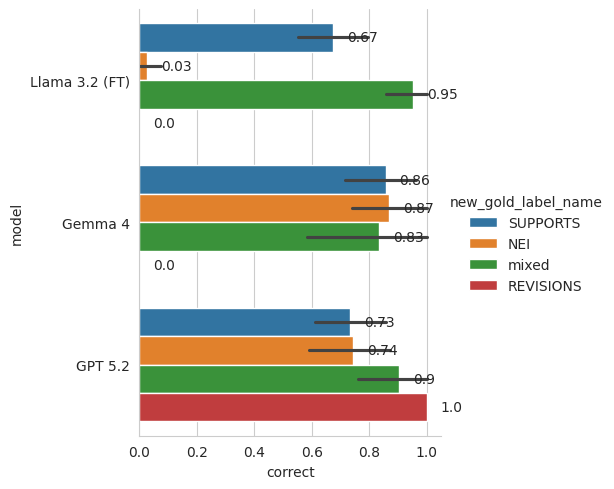

In [59]:
import pandas as pd

def agg_gold_labels(labels):
    s = set()
    for l in labels.dropna().unique():
        s.update(l.split(';'))
    return ';'.join(sorted(s))


def agg_flag_levels(levels):
    levels = set(levels)
    print(levels)

    if 'major' in levels:
        return 'major'

    if 'minor' in levels:
        return 'minor'

    if 'none' in levels:
        return 'none'

    if 'NEI' in levels:
        return 'NEI'
    return 'none'

def check_correct(row):
    return bool(row['predicted_label_name'] in row['new_gold_label_name'].split(';'))
# model_df = doccano_df[['model', 'retrieval', 'generated_text', 'claim.flat', 'document.pmid']].drop_duplicates()
labels_df = df[df.gold_label_name == 'SUPPORTS'].groupby(['claim.flat', 'evidence.flat', 'document.pmid'], dropna=False).agg({'new_gold_label_name': agg_gold_labels, 'flag_level': agg_flag_levels}).reset_index()
print('total documents', labels_df['document.pmid'].nunique())
print('total claims', labels_df['claim.flat'].nunique())
print(df.flag_level.unique())
print(df.flag_level.value_counts())
fig_df = data_df.merge(labels_df, validate='many_to_one')

fig_df['correct'] = fig_df.apply(check_correct, axis=1)
fig_df.loc[fig_df['new_gold_label_name'].str.contains(';'), 'new_gold_label_name'] = 'mixed'
fig_df.loc[fig_df['new_gold_label_name'].fillna('') == '', 'new_gold_label_name'] = fig_df['gold_label_name']

fig_df['freq'] = 1
avg_df = fig_df.groupby(['model', 'retrieval'],dropna=False).agg({'correct': 'mean', 'freq': 'sum'}).reset_index()
avg_df['new_gold_label_name'] = 'avg'
fig = sns.catplot(fig_df, kind='bar', n_boot=1000, errorbar=('ci', 95), x='correct', y='model', hue='new_gold_label_name')
add_bar_labels(fig, fmt=lambda x: round(x, 2), padding=10)


In [60]:
fig_df[fig_df.gold_label_name == 'SUPPORTS']

,assignment.round,auto_accepted,chat,chat_template,chunks,civic.id,claim,claim.flat,corrections,corrections.disease,...,response,correct,document.content_source,filepath.embedding_mode,filepath.pairing_mode,subset,retrieval,new_gold_label_name,flag_level,freq
0,1,NaN,"[{'content': '<claim id=""target""> { ""disease...",llama-3-chat,"[{'chunk.end': 1000, 'chunk.id': '39845329:0-1...",12853,NaN,"{\n ""disease"": ""Angiomatoid Fibrous Histiocyt...",{},NaN,...,NaN,True,PMC,None,None,all,medcpt-goat,SUPPORTS,none,1
1,1,NaN,"[{'content': '<claim id=""target""> { ""disease...",llama-3-chat,"[{'chunk.end': 8200, 'chunk.id': '39845329:720...",12854,NaN,"{\n ""disease"": ""Sarcoma"",\n ""evidenceDirecti...",{},NaN,...,NaN,False,PMC,None,None,all,medcpt-goat,NEI,NEI,1
2,1,NaN,"[{'content': '<claim id=""target""> { ""disease...",llama-3-chat,"[{'chunk.end': 1000, 'chunk.id': '41590375:0-1...",12865,NaN,"{\n ""disease"": ""Lung Non-small Cell Carcinoma...",{},NaN,...,NaN,False,PMC,None,None,all,medcpt-goat,SUPPORTS,none,1
3,1,1.0,"[{'content': '<claim id=""target""> { ""disease...",llama-3-chat,"[{'chunk.end': 1000, 'chunk.id': '21796119:0-1...",12896,NaN,"{\n ""disease"": ""B-cell Non-Hodgkin Lymphoma"",...",{},NaN,...,NaN,True,PMC,None,None,all,medcpt-goat,SUPPORTS,none,1
4,1,NaN,"[{'content': '<claim id=""target""> { ""disease...",llama-3-chat,"[{'chunk.end': 1000, 'chunk.id': '21796119:0-1...",12904,NaN,"{\n ""disease"": ""Diffuse Large B-cell Lymphoma...",{},NaN,...,NaN,False,PMC,None,None,all,medcpt-goat,NEI,NEI,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
281,1,NaN,[{'content': '# Instructions You will be give...,NaN,"[{'chunk.end': 2800, 'chunk.id': '40764304:180...",12951,NaN,"{\n ""disease"": ""Myelodysplastic Syndrome"",\n ...",NaN,NaN,...,"{'choices': [{'finish_reason': 'stop', 'index'...",False,PMC,None,None,all,qwen-mongoose,SUPPORTS,none,1
282,1,NaN,[{'content': '# Instructions You will be give...,NaN,"[{'chunk.end': 1000, 'chunk.id': '37479885:0-1...",12954,NaN,"{\n ""disease"": ""Bladder Urothelial Carcinoma""...",NaN,NaN,...,"{'choices': [{'finish_reason': 'stop', 'index'...",True,PMC,None,None,all,qwen-mongoose,REVISIONS,minor,1
283,1,NaN,[{'content': '# Instructions You will be give...,NaN,"[{'chunk.end': 1000, 'chunk.id': '27265895:0-1...",12962,NaN,"{\n ""disease"": ""Childhood B-cell Acute Lympho...",NaN,NaN,...,"{'choices': [{'finish_reason': 'stop', 'index'...",True,PMC,None,None,all,qwen-mongoose,mixed,minor,1
284,1,NaN,[{'content': '# Instructions You will be give...,NaN,"[{'chunk.end': 1000, 'chunk.id': '33707599:0-1...",12963,NaN,"{\n ""disease"": ""B-cell Adult Acute Lymphocyti...",NaN,NaN,...,"{'choices': [{'finish_reason': 'stop', 'index'...",True,PMC,None,None,all,qwen-mongoose,mixed,minor,1


{'NEI'}
{'NEI'}
{'NEI', 'minor'}
{'minor'}
{'NEI'}
{'NEI'}
{'major'}
{'major'}
{'major'}
{'major'}
{'major'}
{'NEI'}
{'major'}
{'major'}
{'none'}
{'none'}
{'minor', 'none'}
{'minor'}
{'none'}
{'none'}
{'none'}
{'none'}
{'minor', 'none'}
{'NEI'}
{'none'}
{'none'}
{'minor'}
{'minor'}
{'NEI'}
{'NEI'}
{'minor'}
{'minor'}
{'NEI'}
{'NEI', 'minor'}
{'minor', 'none'}
{'none'}
{'minor', 'none'}
{'minor', 'none'}
{'NEI'}
{'NEI'}
{'NEI'}
{'NEI'}
{'minor'}
{'minor'}
{'NEI'}
{'NEI'}
{'NEI'}
{'NEI'}
{'NEI'}
{'NEI'}
{'none'}
{'none'}
{'none'}
{'none'}
{'NEI'}
{'NEI'}
{'NEI'}
{'NEI'}
{'NEI'}
{'NEI'}
{'none'}
{'none'}
{'NEI'}
{'NEI'}
{'none'}
{'none'}
{'NEI'}
{'NEI'}
{'NEI'}
{'NEI'}
{'NEI'}
{'NEI'}
{'NEI'}
{'NEI'}
{'NEI'}
{'NEI'}
{'NEI'}
{'NEI', 'minor'}
{'NEI'}
{'NEI'}
{'none'}
{'none'}
{'NEI'}
{'NEI'}
{'NEI'}
{'NEI'}
{'none'}
{'none'}
{'NEI'}
{'NEI'}
{'minor', 'none'}
{'minor', 'none'}
{'NEI'}
{'NEI'}
{'none'}
{'none'}
{'none'}
{'minor', 'none'}
{'minor'}
{'minor'}
{'none'}
{'none'}
{'minor', 'none'}

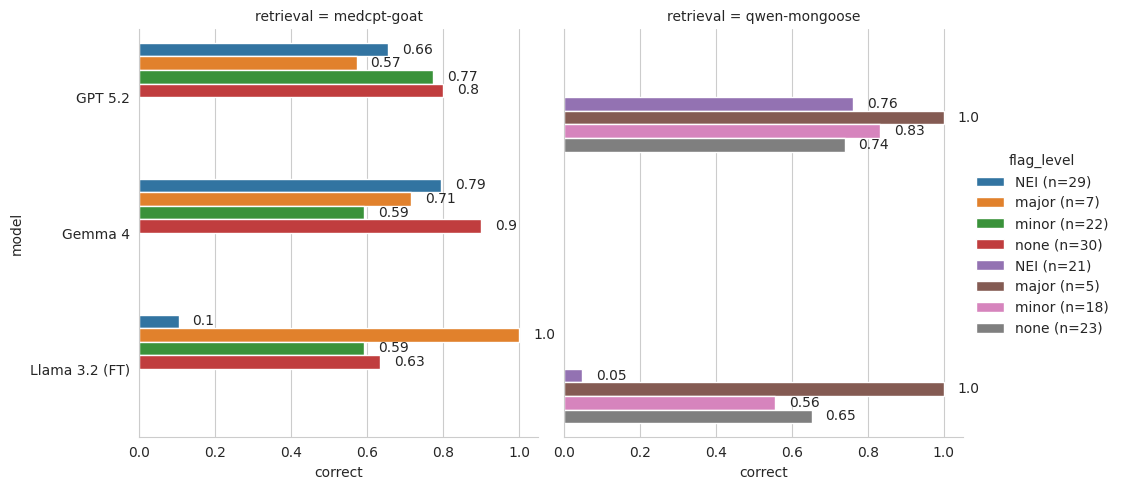

In [61]:
labels_df = df.groupby(['claim.flat', 'evidence.flat', 'document.pmid'], dropna=False).agg({'new_gold_label_name': agg_gold_labels, 'flag_level': agg_flag_levels}).reset_index()
print('total documents', labels_df['document.pmid'].nunique())
print(df.flag_level.unique())
fig_df = data_df.merge(labels_df, validate='many_to_one')

fig_df['correct'] = fig_df.apply(check_correct, axis=1)
fig_df.loc[fig_df['new_gold_label_name'].str.contains(';'), 'new_gold_label_name'] = 'mixed'
fig_df.loc[fig_df['new_gold_label_name'].fillna('') == '', 'new_gold_label_name'] = fig_df['gold_label_name']

fig_df['freq'] = 1
avg_df = fig_df.groupby(['model', 'retrieval', 'flag_level'],dropna=False).agg({'correct': 'mean', 'freq': 'sum'}).reset_index()
avg_df['new_gold_label_name'] = 'avg'
avg_df['flag_level'] = avg_df['flag_level'] + ' (n=' + avg_df['freq'].astype(str) + ')'

fig = sns.catplot(avg_df[avg_df.model.isin({'Llama 3.2 (FT)', 'Gemma 4', 'GPT 5.2'})], kind='bar', col='retrieval', n_boot=1000, errorbar=('ci', 95), x='correct', y='model', hue='flag_level')
add_bar_labels(fig, fmt=lambda x: round(x, 2), padding=10)

## What can we tell about the retrieval?

In [62]:
def classify_retrieval(row):
    ret_type = row['retrieval'].split('-')[0]
    ret_ok_label = f'retrieval_ok_{ret_type}'
    ret_fail_label = f'retrieval_failed_{ret_type}'

    labels = row['instance_labels']

    if {'repurposed_eid', 'requires_supplement', 'requires_image', 'not_in_main_text'} & labels:
        return 'NEI'

    if ret_ok_label in labels and ret_fail_label in labels:
        return 'MIXED'
    elif ret_ok_label in labels:
        return 'OK'
    elif ret_fail_label in labels:
        return 'FAILED'
    elif row['new_gold_label_name'] == 'NEI':
        return 'NEI'
    print(row['document.pmid'], row['row_id'], row['instance_labels'])
    return None


ret_df = df[df.gold_label_name == 'SUPPORTS'].copy()

ret_df['id'] = ret_df['claim.flat'] + ret_df['document.pmid']
ret_df['retrieval_status'] = ret_df.apply(classify_retrieval, axis=1)

ret_df.groupby(['retrieval', 'retrieval_status'], dropna=False).agg({'id': 'nunique', 'document.pmid': 'unique'})

id  \
retrieval     retrieval_status       
medcpt-goat   FAILED             2   
              NEI               23   
              OK                39   
qwen-mongoose FAILED             1   
              MIXED              1   
              NEI               23   
              OK                39   

                                                                    document.pmid  
retrieval     retrieval_status                                                     
medcpt-goat   FAILED                                         [33707599, 41325571]  
              NEI               [21796119, 29533785, 31004019, 34272467, 36050...  
              OK                [17726540, 20570890, 20815032, 21698178, 21796...  
qwen-mongoose FAILED                                                   [29670690]  
              MIXED                                                    [20815032]  
              NEI               [21796119, 29533785, 31004019, 34272467, 36050...  
              OK                [17726540, 20570890, 21698178, 21796119, 27265...